# AIML Practical Assignment 03: Regression Models
## Medical Insurance Cost Prediction

**Practical No.:** 03  
**Subject:** Artificial Intelligence and Machine Learning  
**Application:** Medical Insurance Cost Prediction  
**Dataset:** Medical Cost Personal Dataset (`insurance.csv`) (https://www.kaggle.com/datasets/mirichoi0218/insurance)  
**Target:** Medical insurance charges (`charges`)

**Student name:** Samarth Kadam  
**PRN:** 202401040131  
**Roll number:** 33  
**Division:** A  

> **Dataset context:** This dataset contains individual records with age, sex, BMI, number of children, smoking status, region, and medical insurance charges. The objective is to study regression methods for predicting charges from the available features. The dataset is observational, so associations should not be interpreted as proof of causation.


## 1. Aim

To implement and evaluate Simple Linear Regression, Multiple Linear Regression, and Polynomial Regression using both manual NumPy methods and scikit-learn, and to study Gradient Descent for linear regression on the Medical Cost Personal Dataset.

## 2. Problem statements

1. Develop regression models for a real-world application and evaluate their performance using suitable regression metrics.
2. Implement and analyze Gradient Descent optimization for Linear Regression.

## 3. Objectives

- Load, inspect, and visualize the Medical Cost Personal Dataset.
- Predict medical insurance charges (`charges`) from personal and insurance-related features.
- Implement each of the three regression families manually and with scikit-learn in paired, consecutive sections.
- Compare MAE, MSE, RMSE, and R² on the same held-out test observations.
- Implement Gradient Descent from first principles and compare it with the analytical least-squares solution.
- Understand the role, strengths, and limitations of Lasso regularization.

## 4. Theory and mathematical background

### Simple Linear Regression
For one input feature \(x\), the prediction is \(\hat y=b_0+b_1x\). Ordinary least squares chooses the intercept and slope that minimize the sum of squared residuals.

### Multiple Linear Regression
For \(p\) predictors, \(\hat y=b_0+\sum_{j=1}^{p}b_jx_j\). The design matrix includes a column of ones for the intercept. Categorical inputs such as sex, smoking status, and region are one-hot encoded, with a reference category dropped to avoid redundant columns.

### Polynomial Regression
Polynomial Regression adds nonlinear powers of input features while remaining linear in its coefficients. In this practical, a degree-two polynomial of age is used: \(\hat y=b_0+b_1x+b_2x^2\). Manual and library implementations are compared using the same train-test split.

### Evaluation metrics
- **MAE:** Mean Absolute Error.
- **MSE:** Mean Squared Error.
- **RMSE:** Root Mean Squared Error.
- **R²:** Coefficient of determination.


In [ ]:
# 5. Required library imports
import io
import os
import zipfile
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
warnings.filterwarnings("default")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 6. Dataset loading

The notebook loads the Medical Cost Personal Dataset (`insurance.csv`) from a public dataset mirror. If the download is unavailable, the code raises a clear error rather than silently substituting fabricated data.

In [ ]:
# 6.1 Load data programmatically
INSURANCE_CSV_URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"

try:
    df = pd.read_csv(INSURANCE_CSV_URL)
except Exception as exc:
    raise RuntimeError(
        "Could not download the Medical Cost Personal Dataset. Check the runtime's internet access and retry."
    ) from exc

df.columns = [str(c).strip().lower() for c in df.columns]
expected = ["age", "sex", "bmi", "children", "smoker", "region", "charges"]
missing_cols = [c for c in expected if c not in df.columns]
if missing_cols:
    raise ValueError(f"Dataset is missing expected columns: {missing_cols}. Found: {list(df.columns)}")

df = df[expected].copy()
for col in ["age", "bmi", "children", "charges"]:
    df[col] = pd.to_numeric(df[col], errors="raise")
print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset loaded successfully.
Shape: (768, 10)
Columns: ['Relative Compactness', 'Surface Area', 'Wall Area', 'Roof Area', 'Overall Height', 'Orientation', 'Glazing Area', 'Glazing Area Distribution', 'Y1', 'Y2']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Relative Compactness,Surface Area,Wall Area,Roof Area,Overall Height,Orientation,Glazing Area,Glazing Area Distribution,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


## 7. Dataset exploration and preprocessing

The Medical Cost Personal Dataset contains personal and insurance-related predictors and the target `charges`. We inspect data types, missing values, and summary statistics before splitting the data.

In [ ]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))

print("Missing values per column:")
display(df.isna().sum().to_frame("missing_count"))

print("Descriptive statistics:")
display(df.describe().T)

print("Duplicate rows:", int(df.duplicated().sum()))

Data types:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,dtype
Relative Compactness,float64
Surface Area,float64
Wall Area,float64
Roof Area,float64
Overall Height,float64
Orientation,int64
Glazing Area,float64
Glazing Area Distribution,int64
Y1,float64
Y2,float64


Missing values per column:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,missing_count
Relative Compactness,0
Surface Area,0
Wall Area,0
Roof Area,0
Overall Height,0
Orientation,0
Glazing Area,0
Glazing Area Distribution,0
Y1,0
Y2,0


Descriptive statistics:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,count,mean,std,min,25%,50%,75%,max
Relative Compactness,768.0,0.764167,0.105777,0.62,0.6825,0.75,0.8300,0.98
Surface Area,768.0,671.708333,88.086116,514.50,606.3750,673.75,741.1250,808.50
Wall Area,768.0,318.500000,43.626481,245.00,294.0000,318.50,343.0000,416.50
Roof Area,768.0,176.604167,45.165950,110.25,140.8750,183.75,220.5000,220.50
Overall Height,768.0,5.250000,1.751140,3.50,3.5000,5.25,7.0000,7.00
Orientation,768.0,3.500000,1.118763,2.00,2.7500,3.50,4.2500,5.00
Glazing Area,768.0,0.234375,0.133221,0.00,0.1000,0.25,0.4000,0.40
Glazing Area Distribution,768.0,2.812500,1.550960,0.00,1.7500,3.00,4.0000,5.00
Y1,768.0,22.307195,10.090204,6.01,12.9925,18.95,31.6675,43.10
Y2,768.0,24.587760,9.513306,10.90,15.6200,22.08,33.1325,48.03


Duplicate rows: 0


## 8. Train-test split and exploratory data analysis

The same reproducible split (`random_state=42`) is reused for all six regression implementations. Sex, smoking status, and region are treated as categorical variables in the multiple-regression models. A correlation heatmap is shown for numerical variables; correlation alone does not establish causation.

In [ ]:
FEATURES = ["age", "sex", "bmi", "children", "smoker", "region"]
TARGET = "charges"
CATEGORICAL = ["sex", "smoker", "region"]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]

X = df[FEATURES].copy()
y = pd.to_numeric(df[TARGET], errors="raise").astype(float)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
print("Full dataset:", X.shape)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Target:", TARGET)
print("Numeric predictors:", NUMERIC)
print("Categorical predictors:", CATEGORICAL)

Full dataset: (768, 8)
Training rows: 614 | Test rows: 154
Target: Heating Load (Y1)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


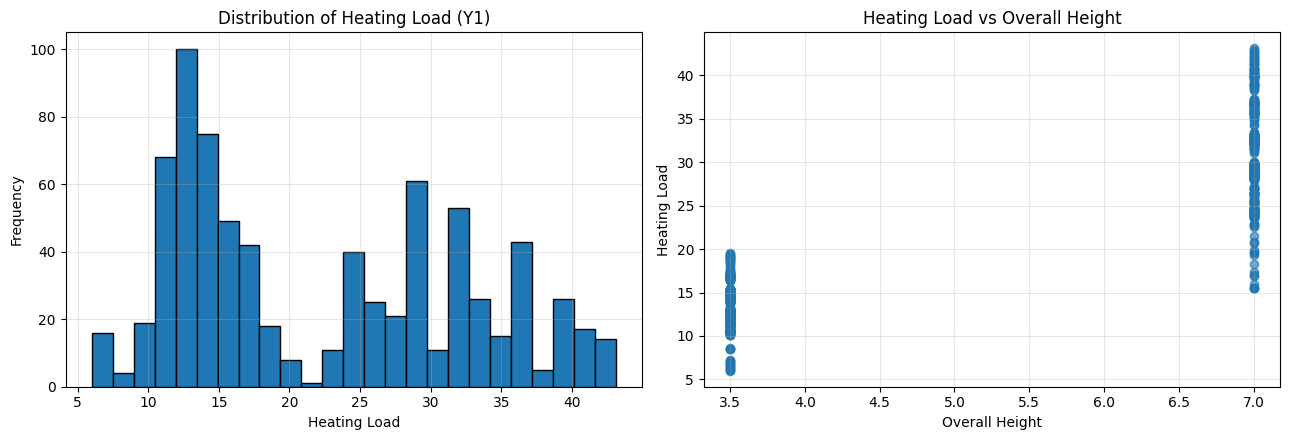

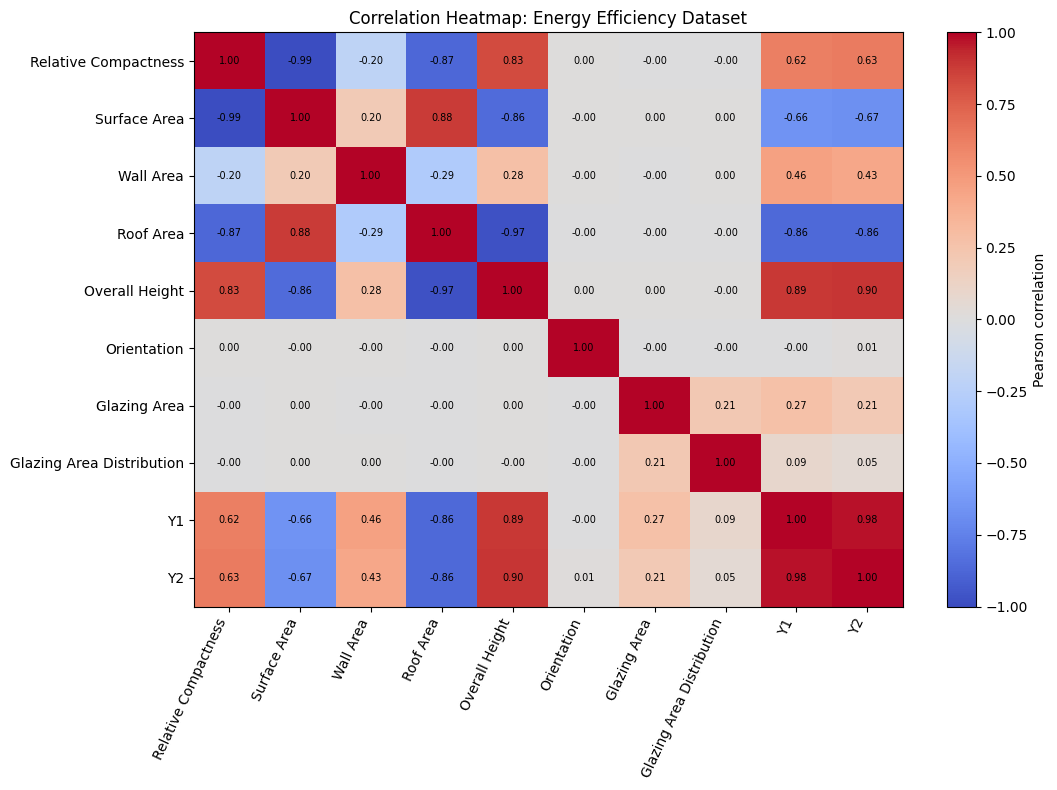

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Target distribution and feature distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(y, bins=25, edgecolor="black")
axes[0].set(title="Distribution of Medical Insurance Charges (charges)", xlabel="Medical Insurance Charges", ylabel="Frequency")
axes[1].scatter(df["age"], y, alpha=0.65)
axes[1].set(title="Medical Insurance Charges vs age", xlabel="age", ylabel="Medical Insurance Charges")
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Correlation heatmap (numeric-coded categories are shown as stored; interpret categorical correlations cautiously)
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=65, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Correlation Heatmap: Medical Insurance Dataset")
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

# 9. Simple Linear Regression Without Libraries

We use **age** as the single predictor. The ordinary least-squares slope is \(b_1=\frac{\sum (x_i-\bar{x})(y_i-\bar{y})}{\sum (x_i-\bar{x})^2}\), and the intercept is \(b_0=\bar{y}-b_1\bar{x}\). NumPy is used for calculations; no regression estimator is used.

In [ ]:
# 9.1 Manual fitting using NumPy
simple_feature = "age"
xtr_s = X_train[simple_feature].to_numpy(dtype=float)
xte_s = X_test[simple_feature].to_numpy(dtype=float)
ytr = y_train.to_numpy(dtype=float)
yte = y_test.to_numpy(dtype=float)

xbar, ybar = xtr_s.mean(), ytr.mean()
denom = np.sum((xtr_s - xbar) ** 2)
if np.isclose(denom, 0):
    raise ValueError("Predictor has no variance; slope cannot be estimated.")
b1_simple_manual = np.sum((xtr_s - xbar) * (ytr - ybar)) / denom
b0_simple_manual = ybar - b1_simple_manual * xbar

pred_simple_manual_train = b0_simple_manual + b1_simple_manual * xtr_s
pred_simple_manual_test = b0_simple_manual + b1_simple_manual * xte_s
assert pred_simple_manual_test.shape == yte.shape
assert np.isfinite(pred_simple_manual_test).all()

def regression_metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MSE": float(mean_squared_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }

metrics_simple_manual = regression_metrics(yte, pred_simple_manual_test)
print(f"Manual equation: Medical Insurance Charges = {b0_simple_manual:.6f} + ({b1_simple_manual:.6f} × age)")
print("Training rows:", len(ytr), "| Test rows:", len(yte))
print(pd.Series(metrics_simple_manual).to_string())

Manual equation: Heating Load = -4.500585 + (5.104975 × Overall Height)
Training rows: 614 | Test rows: 154
MAE      3.644084
MSE     21.680212
RMSE     4.656201
R2       0.792001


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


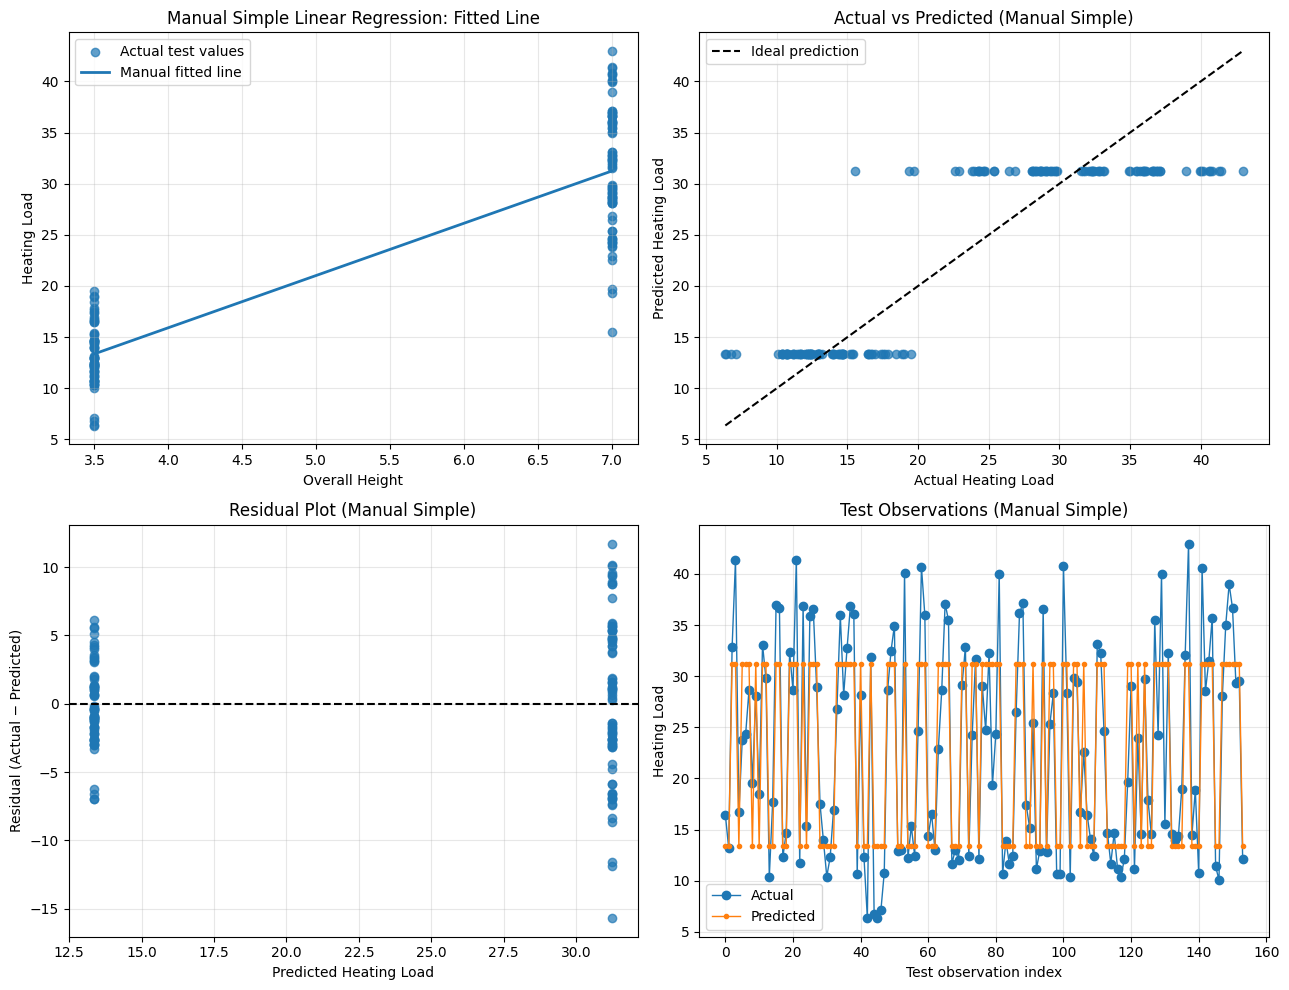

In [ ]:
# 9.2 Required graphs for manual Simple Linear Regression
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

order = np.argsort(xte_s)
axes[0, 0].scatter(xte_s, yte, alpha=0.7, label="Actual test values")
axes[0, 0].plot(xte_s[order], pred_simple_manual_test[order], linewidth=2, label="Manual fitted line")
axes[0, 0].set(title="Manual Simple Linear Regression: Fitted Line", xlabel=simple_feature, ylabel="Medical Insurance Charges")
axes[0, 0].legend()

axes[0, 1].scatter(yte, pred_simple_manual_test, alpha=0.7)
lims = [min(yte.min(), pred_simple_manual_test.min()), max(yte.max(), pred_simple_manual_test.max())]
axes[0, 1].plot(lims, lims, "k--", label="Ideal prediction")
axes[0, 1].set(title="Actual vs Predicted (Manual Simple)", xlabel="Actual Medical Insurance Charges", ylabel="Predicted Medical Insurance Charges")
axes[0, 1].legend()

resid = yte - pred_simple_manual_test
axes[1, 0].scatter(pred_simple_manual_test, resid, alpha=0.7)
axes[1, 0].axhline(0, color="black", linestyle="--")
axes[1, 0].set(title="Residual Plot (Manual Simple)", xlabel="Predicted Medical Insurance Charges", ylabel="Residual (Actual − Predicted)")

idx = np.arange(len(yte))
axes[1, 1].plot(idx, yte, marker="o", label="Actual", linewidth=1)
axes[1, 1].plot(idx, pred_simple_manual_test, marker=".", label="Predicted", linewidth=1)
axes[1, 1].set(title="Test Observations (Manual Simple)", xlabel="Test observation index", ylabel="Medical Insurance Charges")
axes[1, 1].legend()
for ax in axes.flat: ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 10. Simple Linear Regression Using Libraries

This is the immediate library-based counterpart to the manual model. It uses the same feature and split. `LinearRegression` solves the same ordinary least-squares problem, so coefficients and predictions should closely match the manual formulas, apart from floating-point precision.

In [ ]:
simple_sklearn = LinearRegression()
simple_sklearn.fit(X_train[[simple_feature]], y_train)
pred_simple_sklearn_train = simple_sklearn.predict(X_train[[simple_feature]])
pred_simple_sklearn_test = simple_sklearn.predict(X_test[[simple_feature]])
metrics_simple_sklearn = regression_metrics(yte, pred_simple_sklearn_test)

print(f"scikit-learn equation: Medical Insurance Charges = {simple_sklearn.intercept_:.6f} + ({simple_sklearn.coef_[0]:.6f} × {simple_feature})")
print(pd.Series(metrics_simple_sklearn).to_string())
print("Absolute slope difference:", abs(b1_simple_manual - simple_sklearn.coef_[0]))
print("Maximum absolute test prediction difference:", np.max(np.abs(pred_simple_manual_test - pred_simple_sklearn_test)))

scikit-learn equation: Heating Load = -4.500585 + (5.104975 × Overall Height)
MAE      3.644084
MSE     21.680212
RMSE     4.656201
R2       0.792001
Absolute slope difference: 8.881784197001252e-16
Maximum absolute test prediction difference: 3.552713678800501e-15


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


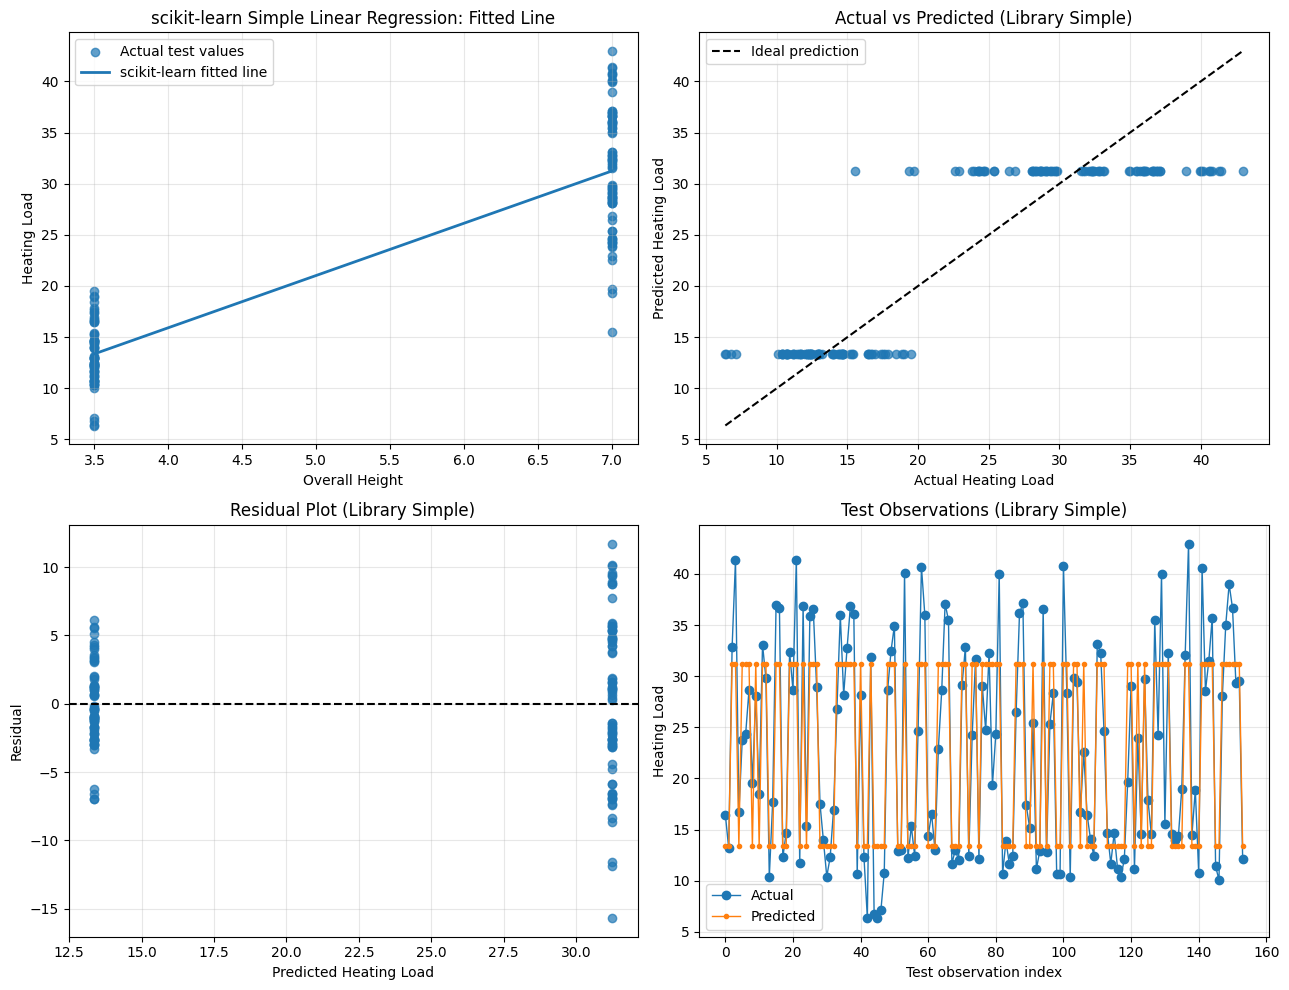

In [ ]:
# Same four graph types for library Simple Linear Regression
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
order = np.argsort(xte_s)
axes[0, 0].scatter(xte_s, yte, alpha=0.7, label="Actual test values")
axes[0, 0].plot(xte_s[order], pred_simple_sklearn_test[order], linewidth=2, label="scikit-learn fitted line")
axes[0, 0].set(title="scikit-learn Simple Linear Regression: Fitted Line", xlabel=simple_feature, ylabel="Medical Insurance Charges")
axes[0, 0].legend()

axes[0, 1].scatter(yte, pred_simple_sklearn_test, alpha=0.7)
lims = [min(yte.min(), pred_simple_sklearn_test.min()), max(yte.max(), pred_simple_sklearn_test.max())]
axes[0, 1].plot(lims, lims, "k--", label="Ideal prediction")
axes[0, 1].set(title="Actual vs Predicted (Library Simple)", xlabel="Actual Medical Insurance Charges", ylabel="Predicted Medical Insurance Charges")
axes[0, 1].legend()

axes[1, 0].scatter(pred_simple_sklearn_test, yte - pred_simple_sklearn_test, alpha=0.7)
axes[1, 0].axhline(0, color="black", linestyle="--")
axes[1, 0].set(title="Residual Plot (Library Simple)", xlabel="Predicted Medical Insurance Charges", ylabel="Residual")

axes[1, 1].plot(np.arange(len(yte)), yte, marker="o", label="Actual", linewidth=1)
axes[1, 1].plot(np.arange(len(yte)), pred_simple_sklearn_test, marker=".", label="Predicted", linewidth=1)
axes[1, 1].set(title="Test Observations (Library Simple)", xlabel="Test observation index", ylabel="Medical Insurance Charges")
axes[1, 1].legend()
for ax in axes.flat: ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 11. Multiple Linear Regression Without Libraries

The manual design matrix contains an intercept, numeric features, and one-hot indicator columns for the two categorical variables. The category levels are determined from the training set only. The first training category is the reference level for each categorical feature, matching drop-first encoding. `numpy.linalg.lstsq` computes the least-squares coefficients without explicitly inverting a matrix.

In [ ]:
# 11.1 Manual preprocessing and fitting
def manual_design_matrices(train_frame, test_frame, numeric_cols, categorical_cols):
    train_parts = [train_frame[numeric_cols].astype(float).reset_index(drop=True)]
    test_parts = [test_frame[numeric_cols].astype(float).reset_index(drop=True)]
    feature_names = list(numeric_cols)
    category_levels = {}
    for col in categorical_cols:
        levels = sorted(pd.Series(train_frame[col].astype(str).unique()).tolist())
        category_levels[col] = levels
        # Drop first category as the reference, using training categories only.
        for level in levels[1:]:
            name = f"{col}={level}"
            train_parts.append(pd.DataFrame({name: (train_frame[col].astype(str).to_numpy() == level).astype(float)}))
            test_parts.append(pd.DataFrame({name: (test_frame[col].astype(str).to_numpy() == level).astype(float)}))
            feature_names.append(name)
    train_df = pd.concat(train_parts, axis=1)
    test_df = pd.concat(test_parts, axis=1)
    # A test-only unseen category, if any, maps to the all-zero reference representation.
    test_df = test_df.reindex(columns=feature_names, fill_value=0.0)
    A_train = np.column_stack([np.ones(len(train_df)), train_df.to_numpy(dtype=float)])
    A_test = np.column_stack([np.ones(len(test_df)), test_df.to_numpy(dtype=float)])
    return A_train, A_test, ["Intercept"] + feature_names, category_levels

A_train_manual, A_test_manual, multi_feature_names, manual_category_levels = manual_design_matrices(
    X_train, X_test, NUMERIC, CATEGORICAL
)
coef_multi_manual, _, _, _ = np.linalg.lstsq(A_train_manual, ytr, rcond=None)
pred_multi_manual_train = A_train_manual @ coef_multi_manual
pred_multi_manual_test = A_test_manual @ coef_multi_manual
assert pred_multi_manual_test.shape == yte.shape
assert np.isfinite(pred_multi_manual_test).all()
metrics_multi_manual = regression_metrics(yte, pred_multi_manual_test)

print("Training category levels:", manual_category_levels)
print("Manual coefficients:")
display(pd.DataFrame({"Feature": multi_feature_names, "Coefficient": coef_multi_manual}))
print("Test metrics:")
display(pd.Series(metrics_multi_manual, name="Value").to_frame())

Training category levels: {'Orientation': ['2', '3', '4', '5'], 'Glazing Area Distribution': ['0', '1', '2', '3', '4', '5']}
Manual coefficients:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Feature,Coefficient
0,Intercept,78.075188
1,Relative Compactness,-62.451877
2,Surface Area,-0.060628
3,Wall Area,0.037153
4,Roof Area,-0.048890
5,Overall Height,4.131436
6,Glazing Area,17.227497
7,Orientation=3,-0.104264
8,Orientation=4,-0.047046
9,Orientation=5,-0.212205


Test metrics:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Value
MAE,2.059036
MSE,8.249976
RMSE,2.872277
R2,0.920850


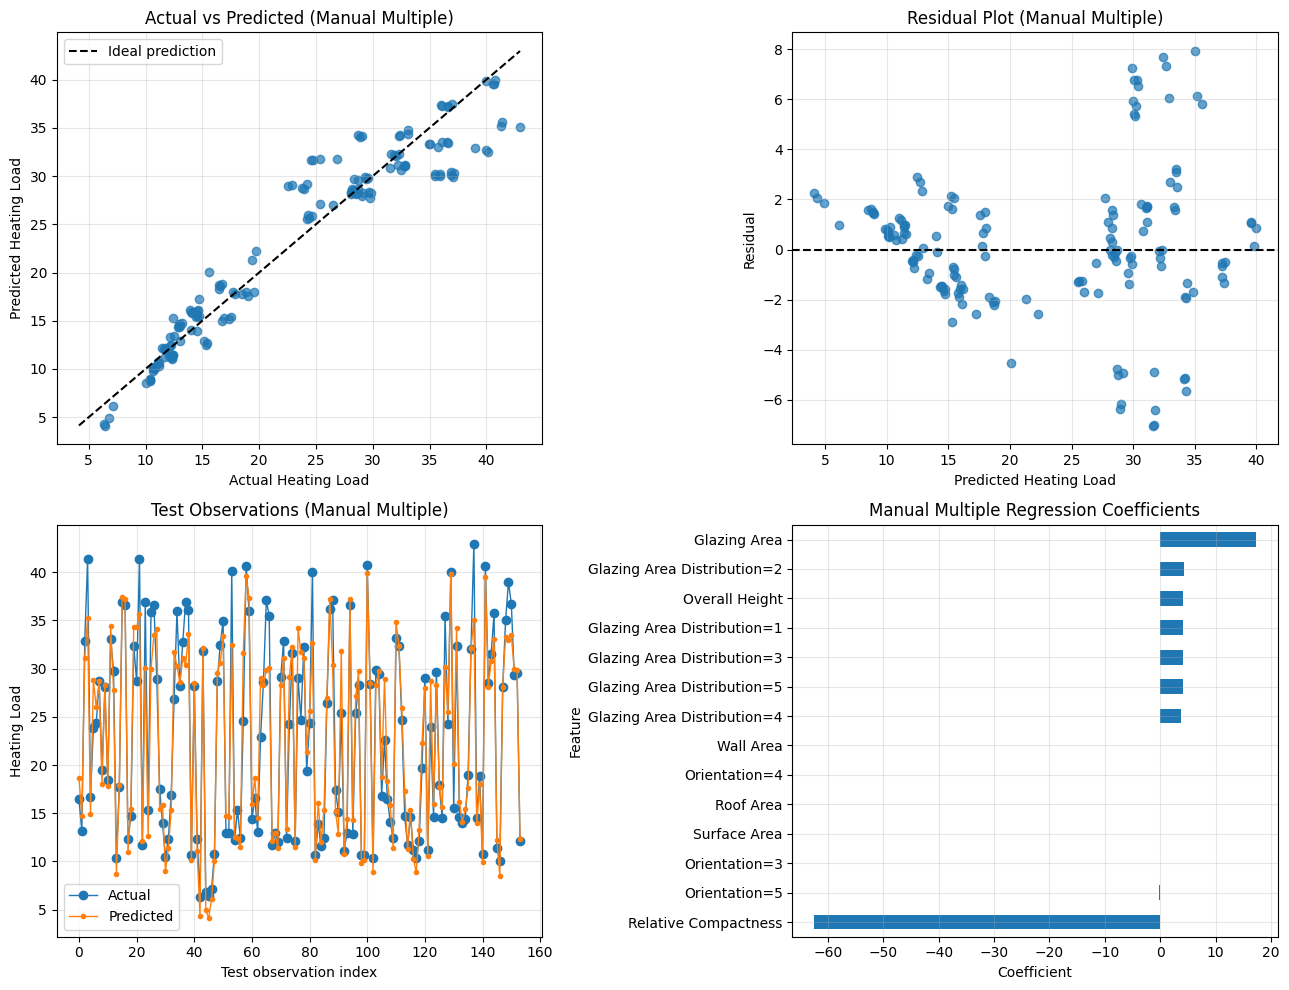

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# 11.2 Evaluation graphs for manual Multiple Linear Regression
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes[0, 0].scatter(yte, pred_multi_manual_test, alpha=0.7)
lims = [min(yte.min(), pred_multi_manual_test.min()), max(yte.max(), pred_multi_manual_test.max())]
axes[0, 0].plot(lims, lims, "k--", label="Ideal prediction")
axes[0, 0].set(title="Actual vs Predicted (Manual Multiple)", xlabel="Actual Medical Insurance Charges", ylabel="Predicted Medical Insurance Charges")
axes[0, 0].legend()

axes[0, 1].scatter(pred_multi_manual_test, yte - pred_multi_manual_test, alpha=0.7)
axes[0, 1].axhline(0, color="black", linestyle="--")
axes[0, 1].set(title="Residual Plot (Manual Multiple)", xlabel="Predicted Medical Insurance Charges", ylabel="Residual")

axes[1, 0].plot(np.arange(len(yte)), yte, marker="o", label="Actual", linewidth=1)
axes[1, 0].plot(np.arange(len(yte)), pred_multi_manual_test, marker=".", label="Predicted", linewidth=1)
axes[1, 0].set(title="Test Observations (Manual Multiple)", xlabel="Test observation index", ylabel="Medical Insurance Charges")
axes[1, 0].legend()

coef_df_manual = pd.DataFrame({"Feature": multi_feature_names[1:], "Coefficient": coef_multi_manual[1:]})
coef_df_manual.sort_values("Coefficient").plot.barh(x="Feature", y="Coefficient", ax=axes[1, 1], legend=False)
axes[1, 1].set(title="Manual Multiple Regression Coefficients", xlabel="Coefficient", ylabel="Feature")
for ax in axes.flat: ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 12. Multiple Linear Regression Using Libraries

`ColumnTransformer` and `OneHotEncoder(drop='first')` encode the categorical features. The transformer is fitted only on training data via the pipeline. Numeric and categorical feature representation matches the manual design matrix, so ordinary least-squares predictions should be very close.

In [ ]:
# Compatibility with both recent and older scikit-learn versions
try:
    onehot = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(drop="first", handle_unknown="ignore", sparse=False)

preprocessor_multi = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", NUMERIC),
        ("categorical", onehot, CATEGORICAL),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)
multi_sklearn = Pipeline([
    ("preprocess", preprocessor_multi),
    ("regression", LinearRegression())
])
multi_sklearn.fit(X_train, y_train)
pred_multi_sklearn_train = multi_sklearn.predict(X_train)
pred_multi_sklearn_test = multi_sklearn.predict(X_test)
metrics_multi_sklearn = regression_metrics(yte, pred_multi_sklearn_test)

feature_names_sklearn = multi_sklearn.named_steps["preprocess"].get_feature_names_out()
coef_multi_sklearn = multi_sklearn.named_steps["regression"].coef_
print("scikit-learn intercept:", multi_sklearn.named_steps["regression"].intercept_)
display(pd.DataFrame({"Feature": feature_names_sklearn, "Coefficient": coef_multi_sklearn}))
display(pd.Series(metrics_multi_sklearn, name="Value").to_frame())
print("Maximum absolute test prediction difference vs manual:",
      np.max(np.abs(pred_multi_manual_test - pred_multi_sklearn_test)))

scikit-learn intercept: 78.07518833033535


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Feature,Coefficient
0,Relative Compactness,-62.451877
1,Surface Area,-0.060628
2,Wall Area,0.037153
3,Roof Area,-0.048890
4,Overall Height,4.131436
5,Glazing Area,17.227497
6,Orientation_3,-0.104264
7,Orientation_4,-0.047046
8,Orientation_5,-0.212205
9,Glazing Area Distribution_1,4.122271


,Value
MAE,2.059036
MSE,8.249976
RMSE,2.872277
R2,0.920850


Maximum absolute test prediction difference vs manual: 1.511679670329613e-11


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


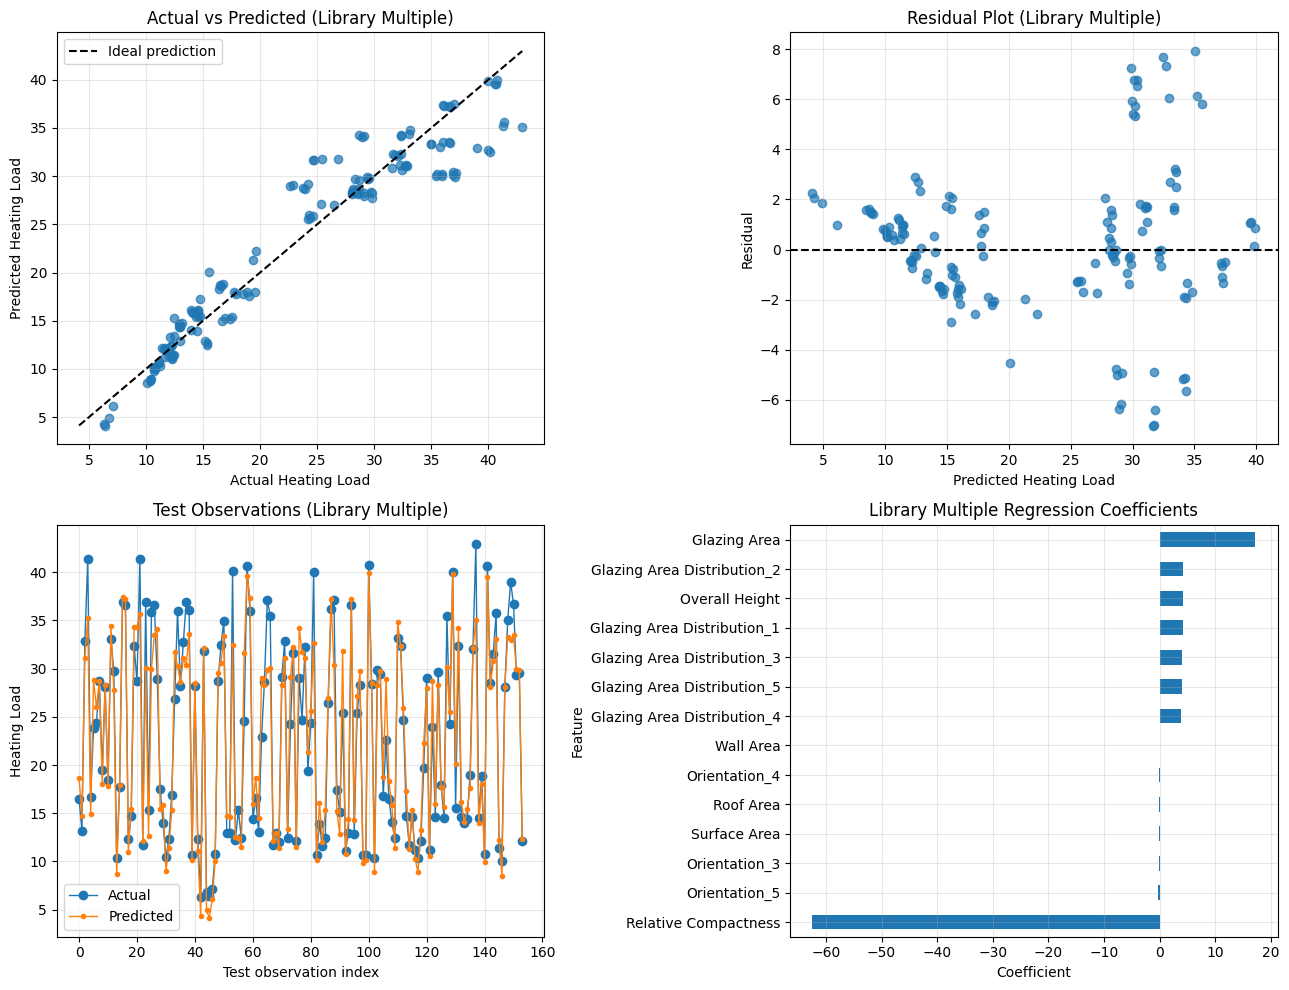

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# 12.2 Evaluation graphs for library Multiple Linear Regression
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes[0, 0].scatter(yte, pred_multi_sklearn_test, alpha=0.7)
lims = [min(yte.min(), pred_multi_sklearn_test.min()), max(yte.max(), pred_multi_sklearn_test.max())]
axes[0, 0].plot(lims, lims, "k--", label="Ideal prediction")
axes[0, 0].set(title="Actual vs Predicted (Library Multiple)", xlabel="Actual Medical Insurance Charges", ylabel="Predicted Medical Insurance Charges")
axes[0, 0].legend()

axes[0, 1].scatter(pred_multi_sklearn_test, yte - pred_multi_sklearn_test, alpha=0.7)
axes[0, 1].axhline(0, color="black", linestyle="--")
axes[0, 1].set(title="Residual Plot (Library Multiple)", xlabel="Predicted Medical Insurance Charges", ylabel="Residual")

axes[1, 0].plot(np.arange(len(yte)), yte, marker="o", label="Actual", linewidth=1)
axes[1, 0].plot(np.arange(len(yte)), pred_multi_sklearn_test, marker=".", label="Predicted", linewidth=1)
axes[1, 0].set(title="Test Observations (Library Multiple)", xlabel="Test observation index", ylabel="Medical Insurance Charges")
axes[1, 0].legend()

coef_df_lib = pd.DataFrame({"Feature": feature_names_sklearn, "Coefficient": coef_multi_sklearn})
coef_df_lib.sort_values("Coefficient").plot.barh(x="Feature", y="Coefficient", ax=axes[1, 1], legend=False)
axes[1, 1].set(title="Library Multiple Regression Coefficients", xlabel="Coefficient", ylabel="Feature")
for ax in axes.flat: ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 13. Polynomial Regression Without Libraries

For a transparent visual demonstration, use age as the single feature and construct columns \([1,x,x^2]\) manually. Coefficients are obtained with `numpy.linalg.lstsq`. This polynomial model is deliberately a one-feature degree-two model, not a multivariable polynomial expansion.

In [ ]:
# 13.1 Manual degree-two polynomial model
xtr_p = X_train[[simple_feature]].to_numpy(dtype=float).ravel()
xte_p = X_test[[simple_feature]].to_numpy(dtype=float).ravel()
P_train_manual = np.column_stack([np.ones(len(xtr_p)), xtr_p, xtr_p ** 2])
P_test_manual = np.column_stack([np.ones(len(xte_p)), xte_p, xte_p ** 2])
coef_poly_manual, _, _, _ = np.linalg.lstsq(P_train_manual, ytr, rcond=None)
pred_poly_manual_train = P_train_manual @ coef_poly_manual
pred_poly_manual_test = P_test_manual @ coef_poly_manual
assert pred_poly_manual_test.shape == yte.shape
assert np.isfinite(pred_poly_manual_test).all()
metrics_poly_manual = regression_metrics(yte, pred_poly_manual_test)
print(f"Manual polynomial equation: ŷ = {coef_poly_manual[0]:.6f} + ({coef_poly_manual[1]:.6f})x + ({coef_poly_manual[2]:.6f})x²")
display(pd.Series(metrics_poly_manual, name="Value").to_frame())

Manual polynomial equation: ŷ = 1.142045 + (2.686705)x + (0.230311)x²


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Value
MAE,3.644084
MSE,21.680212
RMSE,4.656201
R2,0.792001


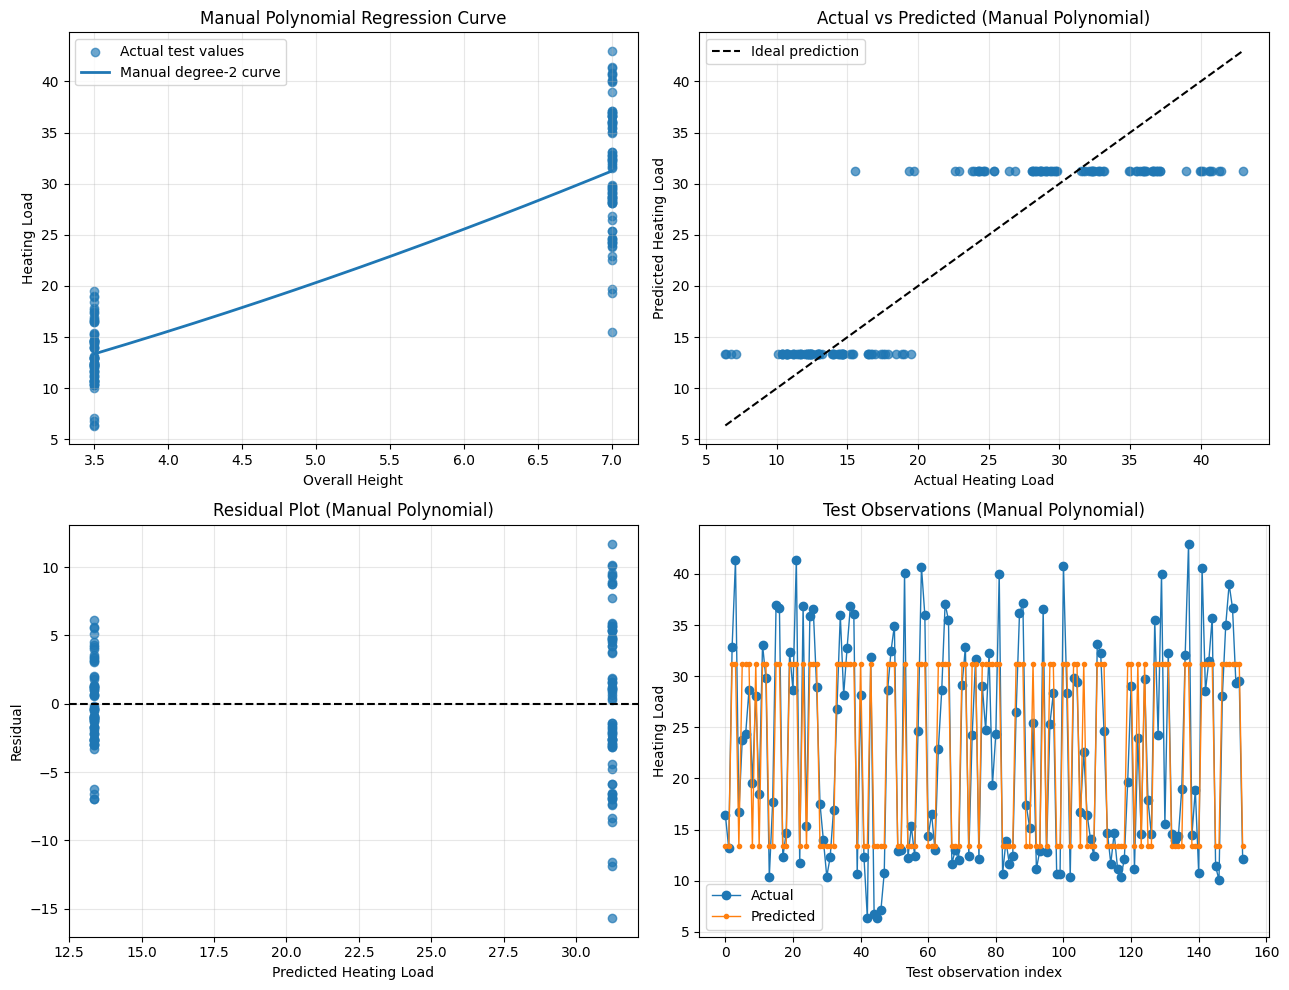

In [ ]:
# 13.2 Required graphs for manual Polynomial Regression
grid_x = np.linspace(X_train[simple_feature].min(), X_train[simple_feature].max(), 250)
grid_pred_manual = coef_poly_manual[0] + coef_poly_manual[1] * grid_x + coef_poly_manual[2] * grid_x**2

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes[0, 0].scatter(xte_p, yte, alpha=0.65, label="Actual test values")
axes[0, 0].plot(grid_x, grid_pred_manual, linewidth=2, label="Manual degree-2 curve")
axes[0, 0].set(title="Manual Polynomial Regression Curve", xlabel=simple_feature, ylabel="Medical Insurance Charges")
axes[0, 0].legend()

axes[0, 1].scatter(yte, pred_poly_manual_test, alpha=0.7)
lims = [min(yte.min(), pred_poly_manual_test.min()), max(yte.max(), pred_poly_manual_test.max())]
axes[0, 1].plot(lims, lims, "k--", label="Ideal prediction")
axes[0, 1].set(title="Actual vs Predicted (Manual Polynomial)", xlabel="Actual Medical Insurance Charges", ylabel="Predicted Medical Insurance Charges")
axes[0, 1].legend()

axes[1, 0].scatter(pred_poly_manual_test, yte - pred_poly_manual_test, alpha=0.7)
axes[1, 0].axhline(0, color="black", linestyle="--")
axes[1, 0].set(title="Residual Plot (Manual Polynomial)", xlabel="Predicted Medical Insurance Charges", ylabel="Residual")

axes[1, 1].plot(np.arange(len(yte)), yte, marker="o", label="Actual", linewidth=1)
axes[1, 1].plot(np.arange(len(yte)), pred_poly_manual_test, marker=".", label="Predicted", linewidth=1)
axes[1, 1].set(title="Test Observations (Manual Polynomial)", xlabel="Test observation index", ylabel="Medical Insurance Charges")
axes[1, 1].legend()
for ax in axes.flat: ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 14. Polynomial Regression Using Libraries

`PolynomialFeatures(degree=2, include_bias=False)` creates the \(x\) and \(x^2\) columns, and `LinearRegression` estimates the coefficients. The estimator supplies the intercept, so a duplicated bias column is avoided. The transformation is fitted within a pipeline on training data only.

In [ ]:
poly_sklearn = Pipeline([
    ("polynomial_features", PolynomialFeatures(degree=2, include_bias=False)),
    ("regression", LinearRegression())
])
poly_sklearn.fit(X_train[[simple_feature]], y_train)
pred_poly_sklearn_train = poly_sklearn.predict(X_train[[simple_feature]])
pred_poly_sklearn_test = poly_sklearn.predict(X_test[[simple_feature]])
metrics_poly_sklearn = regression_metrics(yte, pred_poly_sklearn_test)
poly_reg = poly_sklearn.named_steps["regression"]
print(f"scikit-learn polynomial equation: ŷ = {poly_reg.intercept_:.6f} + ({poly_reg.coef_[0]:.6f})x + ({poly_reg.coef_[1]:.6f})x²")
display(pd.Series(metrics_poly_sklearn, name="Value").to_frame())
print("Maximum absolute test prediction difference vs manual:",
      np.max(np.abs(pred_poly_manual_test - pred_poly_sklearn_test)))

scikit-learn polynomial equation: ŷ = 7.303952 + (0.045887)x + (0.481818)x²


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Value
MAE,3.644084
MSE,21.680212
RMSE,4.656201
R2,0.792001


Maximum absolute test prediction difference vs manual: 1.0302869668521453e-13


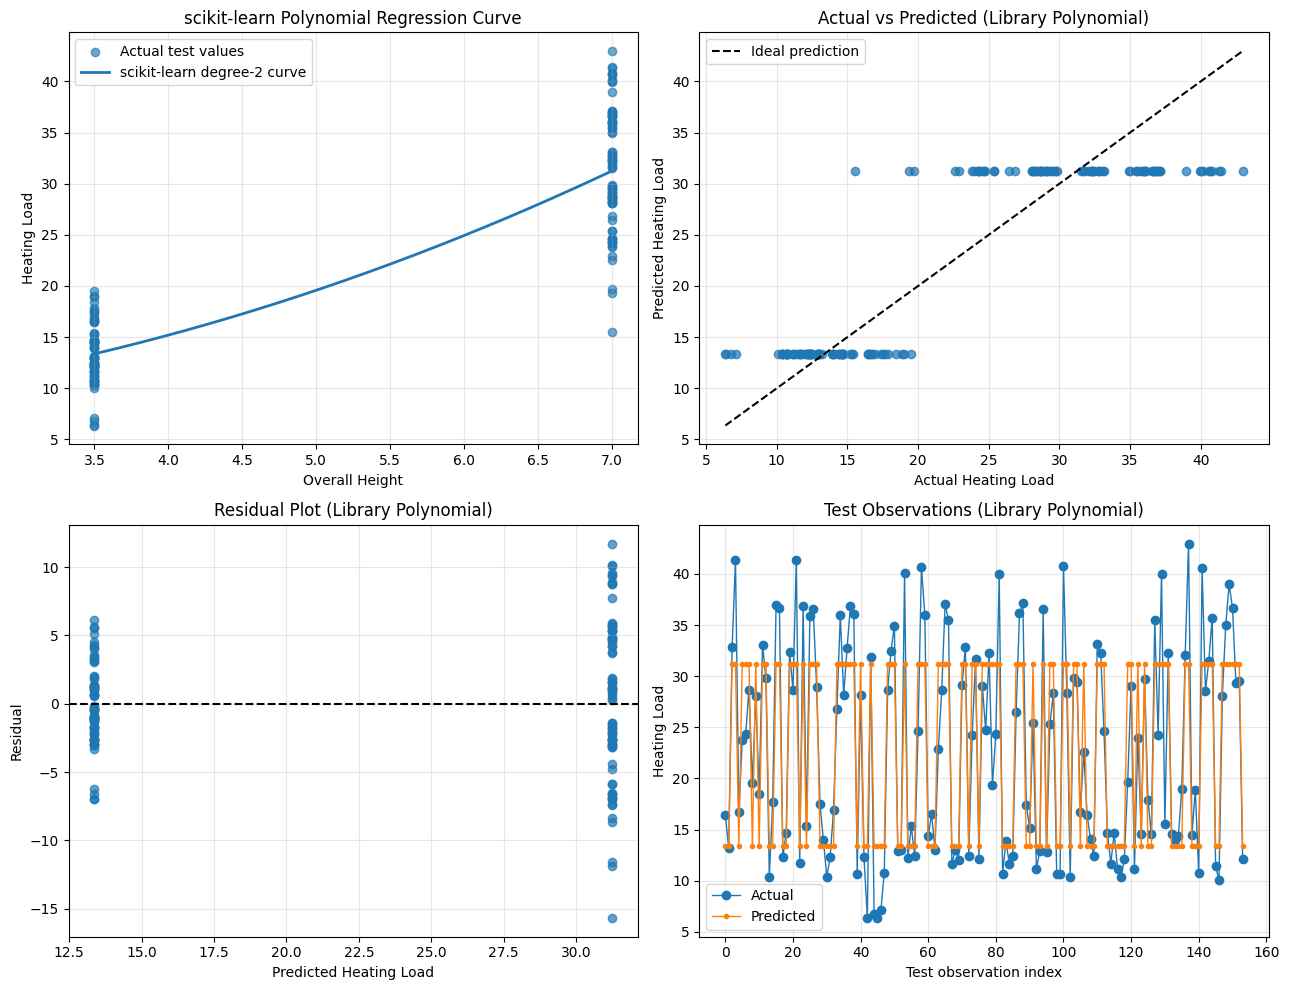

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# 14.2 Required graphs for library Polynomial Regression
grid_frame = pd.DataFrame({simple_feature: grid_x})
grid_pred_lib = poly_sklearn.predict(grid_frame)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes[0, 0].scatter(xte_p, yte, alpha=0.65, label="Actual test values")
axes[0, 0].plot(grid_x, grid_pred_lib, linewidth=2, label="scikit-learn degree-2 curve")
axes[0, 0].set(title="scikit-learn Polynomial Regression Curve", xlabel=simple_feature, ylabel="Medical Insurance Charges")
axes[0, 0].legend()

axes[0, 1].scatter(yte, pred_poly_sklearn_test, alpha=0.7)
lims = [min(yte.min(), pred_poly_sklearn_test.min()), max(yte.max(), pred_poly_sklearn_test.max())]
axes[0, 1].plot(lims, lims, "k--", label="Ideal prediction")
axes[0, 1].set(title="Actual vs Predicted (Library Polynomial)", xlabel="Actual Medical Insurance Charges", ylabel="Predicted Medical Insurance Charges")
axes[0, 1].legend()

axes[1, 0].scatter(pred_poly_sklearn_test, yte - pred_poly_sklearn_test, alpha=0.7)
axes[1, 0].axhline(0, color="black", linestyle="--")
axes[1, 0].set(title="Residual Plot (Library Polynomial)", xlabel="Predicted Medical Insurance Charges", ylabel="Residual")

axes[1, 1].plot(np.arange(len(yte)), yte, marker="o", label="Actual", linewidth=1)
axes[1, 1].plot(np.arange(len(yte)), pred_poly_sklearn_test, marker=".", label="Predicted", linewidth=1)
axes[1, 1].set(title="Test Observations (Library Polynomial)", xlabel="Test observation index", ylabel="Medical Insurance Charges")
axes[1, 1].legend()
for ax in axes.flat: ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 15. Comparison of all six regression implementations

The following table is computed from test predictions—not hardcoded. Corresponding manual/library predictions are compared using maximum absolute difference and mean absolute difference. A paired implementation should agree closely when both use equivalent design matrices and objectives.

In [ ]:
results = [
    ("Simple Linear Regression — Manual", metrics_simple_manual),
    ("Simple Linear Regression — scikit-learn", metrics_simple_sklearn),
    ("Multiple Linear Regression — Manual", metrics_multi_manual),
    ("Multiple Linear Regression — scikit-learn", metrics_multi_sklearn),
    ("Polynomial Regression — Manual", metrics_poly_manual),
    ("Polynomial Regression — scikit-learn", metrics_poly_sklearn),
]
comparison = pd.DataFrame([
    {"Model": name, **metrics} for name, metrics in results
]).set_index("Model")
display(comparison.round(5))

paired_diffs = pd.DataFrame([
    {
        "Model pair": "Simple Linear",
        "Maximum |prediction difference|": float(np.max(np.abs(pred_simple_manual_test - pred_simple_sklearn_test))),
        "Mean |prediction difference|": float(np.mean(np.abs(pred_simple_manual_test - pred_simple_sklearn_test))),
    },
    {
        "Model pair": "Multiple Linear",
        "Maximum |prediction difference|": float(np.max(np.abs(pred_multi_manual_test - pred_multi_sklearn_test))),
        "Mean |prediction difference|": float(np.mean(np.abs(pred_multi_manual_test - pred_multi_sklearn_test))),
    },
    {
        "Model pair": "Polynomial degree 2",
        "Maximum |prediction difference|": float(np.max(np.abs(pred_poly_manual_test - pred_poly_sklearn_test))),
        "Mean |prediction difference|": float(np.mean(np.abs(pred_poly_manual_test - pred_poly_sklearn_test))),
    },
])
display(paired_diffs.round(10))

,MAE,MSE,RMSE,R2
Model,,,,
Simple Linear Regression — Manual,3.64408,21.68021,4.65620,0.79200
Simple Linear Regression — scikit-learn,3.64408,21.68021,4.65620,0.79200
Multiple Linear Regression — Manual,2.05904,8.24998,2.87228,0.92085
Multiple Linear Regression — scikit-learn,2.05904,8.24998,2.87228,0.92085
Polynomial Regression — Manual,3.64408,21.68021,4.65620,0.79200
Polynomial Regression — scikit-learn,3.64408,21.68021,4.65620,0.79200


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Model pair,Maximum |prediction difference|,Mean |prediction difference|
0,Simple Linear,0.0,0.0
1,Multiple Linear,0.0,0.0
2,Polynomial degree 2,0.0,0.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


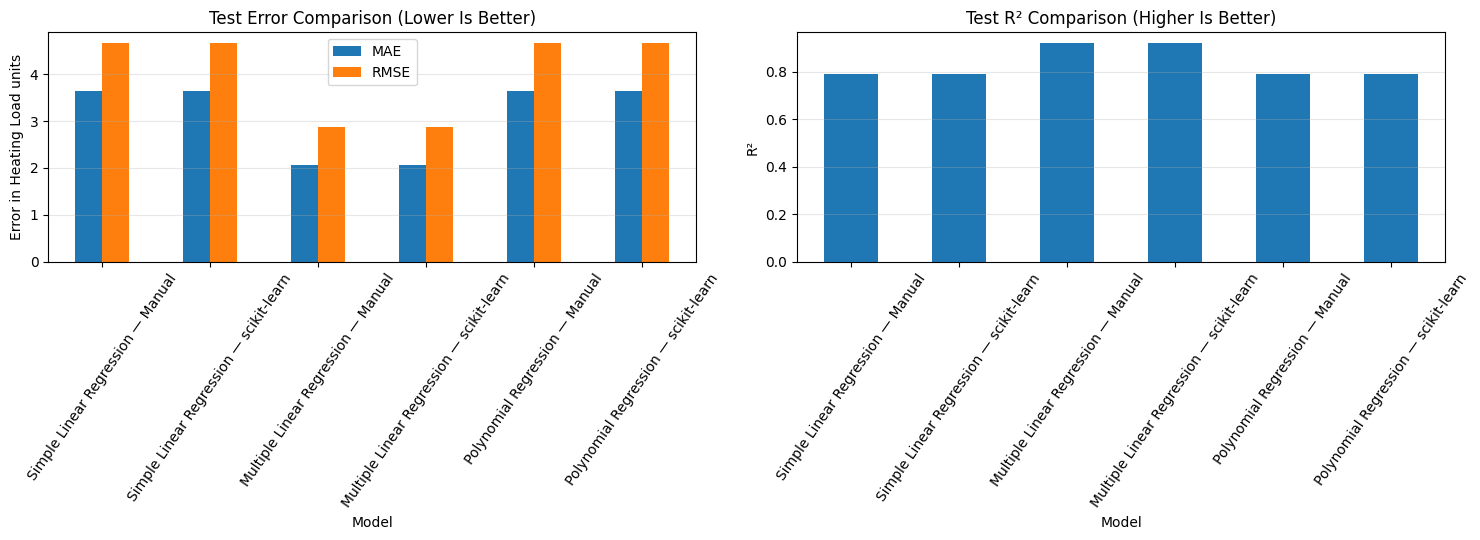

Lowest test RMSE: Multiple Linear Regression — scikit-learn (2.8723)
Highest test R²: Multiple Linear Regression — scikit-learn (0.9209)
Interpretation: compare error and R² together; more complex models do not automatically generalize better.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Performance comparison chart: MAE and RMSE are in target units; R² is unitless.
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
comparison[["MAE", "RMSE"]].plot(kind="bar", ax=axes[0])
axes[0].set(title="Test Error Comparison (Lower Is Better)", ylabel="Error in Medical Insurance Charges units", xlabel="Model")
axes[0].tick_params(axis="x", rotation=55)
axes[0].grid(axis="y", alpha=0.3)
comparison[["R2"]].plot(kind="bar", ax=axes[1], legend=False)
axes[1].set(title="Test R² Comparison (Higher Is Better)", ylabel="R²", xlabel="Model")
axes[1].tick_params(axis="x", rotation=55)
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

best_rmse = comparison["RMSE"].idxmin()
best_r2 = comparison["R2"].idxmax()
print("Lowest test RMSE:", best_rmse, f"({comparison.loc[best_rmse, 'RMSE']:.4f})")
print("Highest test R²:", best_r2, f"({comparison.loc[best_r2, 'R2']:.4f})")
print("Interpretation: compare error and R² together; more complex models do not automatically generalize better.")

## 16. Manual Gradient Descent for Linear Regression

Gradient Descent iteratively updates parameters to reduce mean squared error. To improve numerical stability, age is standardized using a scaler fitted only on the training data. The optimized model is converted back to the original feature scale for reporting. For cost \(J=(1/2m)\sum(\hat y-y)^2\), gradients are \(\partial J/\partial b_0=\mathrm{mean}(\hat y-y)\) and \(\partial J/\partial b_1=\mathrm{mean}((\hat y-y)z)\).

In [ ]:
# 16.1 Scale using training data only, then run manual batch Gradient Descent
scaler_gd = StandardScaler()
z_train = scaler_gd.fit_transform(X_train[[simple_feature]]).ravel()
z_test = scaler_gd.transform(X_test[[simple_feature]]).ravel()

gd_intercept = 0.0
gd_slope = 0.0
learning_rate = 0.05
n_iterations = 5000
m = len(ytr)
cost_history = []

for iteration in range(n_iterations):
    y_hat = gd_intercept + gd_slope * z_train
    errors = y_hat - ytr
    cost = np.sum(errors ** 2) / (2 * m)
    cost_history.append(cost)
    grad_intercept = np.mean(errors)
    grad_slope = np.mean(errors * z_train)
    gd_intercept -= learning_rate * grad_intercept
    gd_slope -= learning_rate * grad_slope

# Convert parameters from standardized z=(x-mean)/scale to original x units.
scale_gd = float(scaler_gd.scale_[0])
mean_gd = float(scaler_gd.mean_[0])
gd_slope_original = gd_slope / scale_gd
gd_intercept_original = gd_intercept - gd_slope * mean_gd / scale_gd

pred_gd_train = gd_intercept + gd_slope * z_train
pred_gd_test = gd_intercept + gd_slope * z_test
metrics_gd = regression_metrics(yte, pred_gd_test)
print(f"GD standardized parameters: intercept={gd_intercept:.6f}, slope={gd_slope:.6f}")
print(f"GD original-scale equation: Medical Insurance Charges = {gd_intercept_original:.6f} + ({gd_slope_original:.6f} × {simple_feature})")
display(pd.Series(metrics_gd, name="Value").to_frame())

GD standardized parameters: intercept=22.155033, slope=8.932521
GD original-scale equation: Heating Load = -4.500585 + (5.104975 × Overall Height)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Value
MAE,3.644084
MSE,21.680212
RMSE,4.656201
R2,0.792001


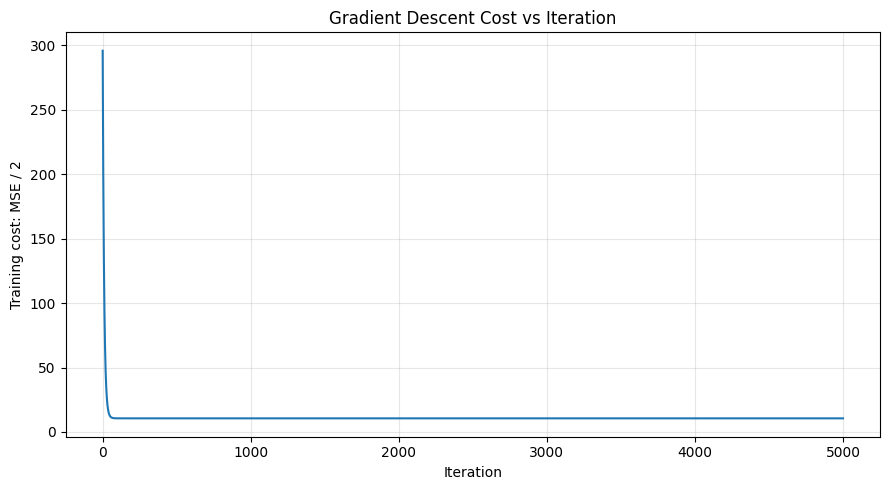

Analytical least-squares intercept: -4.500584564442182
Gradient Descent intercept (original scale): -4.5005845644421605
Analytical least-squares slope: 5.104974710719744
Gradient Descent slope (original scale): 5.104974710719734
Absolute intercept difference: 2.1316282072803006e-14
Absolute slope difference: 9.769962616701378e-15
Analytical test metrics: {'MAE': 3.644084217107396, 'MSE': 21.680211915802914, 'RMSE': 4.656201447081399, 'R2': 0.7920012396798621}
Gradient Descent test metrics: {'MAE': 3.6440842171073955, 'MSE': 21.680211915802925, 'RMSE': 4.656201447081401, 'R2': 0.7920012396798621}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# 16.2 Convergence and analytical least-squares comparison
plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, n_iterations + 1), cost_history)
plt.title("Gradient Descent Cost vs Iteration")
plt.xlabel("Iteration")
plt.ylabel("Training cost: MSE / 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Analytical simple least-squares solution on the same training observations
analytical_slope = b1_simple_manual
analytical_intercept = b0_simple_manual
print("Analytical least-squares intercept:", analytical_intercept)
print("Gradient Descent intercept (original scale):", gd_intercept_original)
print("Analytical least-squares slope:", analytical_slope)
print("Gradient Descent slope (original scale):", gd_slope_original)
print("Absolute intercept difference:", abs(analytical_intercept - gd_intercept_original))
print("Absolute slope difference:", abs(analytical_slope - gd_slope_original))
print("Analytical test metrics:", regression_metrics(yte, pred_simple_manual_test))
print("Gradient Descent test metrics:", metrics_gd)

## 17. Overall results and comparative observations

Use the computed tables and charts above to make evidence-based observations.

- The simple model uses only age, so it may miss information carried by BMI, number of children, smoking status, sex, and region.
- Multiple Linear Regression uses the complete feature set, including one-hot encoded categorical features.
- Polynomial Regression can represent curvature in the age relationship, but it still uses only one input feature in this demonstration.
- The paired manual and scikit-learn versions should give nearly identical predictions because they solve equivalent least-squares problems.
- A more complex model is not guaranteed to perform best on held-out data. The test metrics estimate generalization for this split; they do not establish causal relationships or guarantee performance on other insurance populations.
- Gradient Descent should reduce its cost and approach the analytical solution when the learning rate and iteration count are suitable. A small remaining difference can occur because the iterative optimizer stops after a finite number of updates.

# 18. Lasso Regression: Theory and Insights

## 18.1 Definition

Lasso Regression stands for **Least Absolute Shrinkage and Selection Operator**. It is a regularized linear regression method that adds an L1 penalty to the ordinary least-squares loss. The penalty discourages unnecessarily large coefficients and can set some coefficients exactly to zero.

## 18.2 Mathematical Equation

\[
\min_{\beta_0,\boldsymbol{\beta}}
\left[
\frac{1}{2n}\sum_{i=1}^{n}
(y_i-\beta_0-\mathbf{x}_i^\top\boldsymbol{\beta})^2
+\alpha\sum_{j=1}^{p}|\beta_j|
\right]
\]

Here:

- \(n\): number of training observations.
- \(p\): number of predictors.
- \(y_i\): actual target value for observation \(i\).
- \(\hat y_i=\beta_0+\mathbf{x}_i^\top\boldsymbol{\beta}\): predicted target.
- \(\beta_0\): intercept.
- \(\beta_j\): coefficient of predictor \(j\).
- \(\alpha\): regularization strength.
- \(\sum_{j=1}^{p}|\beta_j|\): L1 penalty, the sum of absolute coefficient values.

In the standard scikit-learn `Lasso` formulation, the intercept is generally not penalized. The precise numerical scaling of the loss term can differ across textbook conventions and software APIs; the key idea is the squared-error objective plus an L1 coefficient penalty.

## 18.3 Working Principle

Ordinary least squares chooses coefficients to minimize squared prediction error. Lasso balances that fit against a penalty on coefficient magnitudes:

1. Large absolute coefficients increase the penalty.
2. The optimization shrinks coefficients toward zero.
3. Unlike many other shrinkage methods, L1 regularization can make coefficients exactly zero.
4. Predictors whose fitted coefficients become zero are excluded from the resulting linear prediction equation.

This creates a form of embedded feature selection and can make a model more compact. With correlated predictors, Lasso may select one variable over another in ways that vary with the sample, so selection should not be treated as definitive proof of physical importance.

## 18.4 Difference Between Linear Regression and Lasso Regression

| Aspect | Ordinary Linear Regression (OLS) | Lasso Regression |
|---|---|---|
| Objective function | Minimizes squared residuals | Minimizes squared residuals plus an L1 penalty |
| Regularization | No coefficient penalty | Controlled by \(\alpha\) |
| Coefficient shrinkage | No explicit shrinkage | Shrinks coefficient magnitudes toward zero |
| Feature selection | Usually retains all represented predictors | Can set some coefficients exactly to zero |
| Model complexity | Can become unnecessarily complex with many predictors | Can produce a sparser model |
| Interpretability | Coefficients are interpretable, but many may remain | Sparsity can make the model easier to summarize |
| Potential underfitting | Possible if the model form is too simple | More likely if regularization is too strong |
| Typical use cases | Baseline prediction and estimating linear relationships | Prediction with many predictors, correlated inputs, or a need for a sparse model |

## 18.5 Role of Alpha

The regularization parameter \(\alpha\) controls the trade-off between fitting the training data and keeping coefficients small.

- **Small alpha:** the penalty is weak; results tend to be closer to ordinary least squares, with less shrinkage and potentially less bias.
- **Moderate alpha:** coefficients are more strongly shrunk; some may become zero, potentially improving generalization when the unregularized model is too variable.
- **Large alpha:** the penalty dominates; many coefficients may approach or become zero, and the model can underfit.

The best \(\alpha\) depends on the dataset, feature scaling, encoding, and noise. Choose it using a validation set or cross-validation confined to the training data. Do not repeatedly tune \(\alpha\) against the final test set, because that leaks test-set information into model selection.

## 18.6 Advantages

- **Feature selection:** exact zero coefficients can reduce the number of active predictors.
- **Reduced model complexity:** a sparse coefficient vector can be easier to inspect and communicate.
- **Potentially less overfitting:** regularization can improve generalization when OLS coefficients are unstable.
- **Improved interpretability:** a smaller set of nonzero coefficients can make the prediction rule more compact.

These benefits are conditional, not guaranteed. They depend on the data, model specification, and regularization strength.

## 18.7 Limitations

- **Sensitivity to feature scaling:** the same penalty acts on coefficient magnitudes, so differently scaled features can be penalized unequally in practical terms. Scale numeric predictors using training-only statistics.
- **Potential underfitting:** excessive regularization can suppress useful signal.
- **Correlated predictors:** when predictors are strongly correlated, Lasso may choose one and suppress others; selected features can be unstable across samples.
- **Information loss:** an overly large penalty can shrink genuinely useful coefficients too much.
- **Interpretation caution:** a zero coefficient does not prove that the corresponding real-world building feature has no physical effect. It only indicates that the fitted, penalized model did not retain a nonzero coefficient under that specification and penalty.

## 18.8 Lasso in the Medical Insurance Application

Lasso could be applied to predict Medical Insurance Charges (`charges`) from building-design inputs such as age, bmi, children, smoker, age, insurance features, and encoded categorical variables. Numeric predictors should generally be standardized using a scaler fitted only on training data because the L1 penalty depends on coefficient magnitudes. sex and region should be encoded as categorical inputs (for example, one-hot encoding); their dummy variables then participate in regularization.

Lasso may help when several inputs carry overlapping information or when a compact model is desirable. However, building-design variables can be correlated by construction, so a zero coefficient should be interpreted cautiously. This practical does not report an experimental Lasso score because Lasso is included here as a theory and analytical-insights section, not as an additional fitted model. If a Lasso experiment is added later, it should use the same train-test split as OLS, training-only preprocessing, and the same MAE, MSE, RMSE, and R² metrics.

## 18.9 Final Insights

- Lasso is useful when coefficient shrinkage and a sparse prediction equation are desirable.
- Ordinary least squares minimizes squared error; Lasso minimizes squared error plus an L1 penalty.
- Increasing \(\alpha\) generally increases shrinkage and can simplify the model, but excessive regularization can underfit.
- Model quality must be evaluated empirically on data not used for fitting or tuning.
- Feature selection is a statistical modeling outcome, not proof of causality or proof that a physical feature is irrelevant.

# 19. Conclusion

In this practical, medical insurance charges (`charges`) were modeled using Simple Linear Regression, Multiple Linear Regression, and degree-two Polynomial Regression. Each model was implemented first with manual NumPy calculations and immediately afterward with the corresponding scikit-learn estimator. The common train-test split, evaluation metrics, visualizations, and paired prediction comparisons make the implementations directly comparable.

The final conclusion about which model performs best should be based on the **computed test-set metrics** above, rather than assuming that the most complex model must win. Manual and library-based implementations should agree closely when their design matrices and objectives match. Gradient Descent demonstrates iterative optimization and can be checked against the analytical least-squares solution. Lasso adds an L1 penalty that can shrink coefficients and perform feature selection, but its regularization strength requires careful training-only validation.